# Exploratory Data Analysis (EDA) - Google Play Store Apps
**Author:** Suresh Kumar Shah

### Project Objective
The objective of this project is to conduct a complete Exploratory Data Analysis (EDA) on the Google Play Store dataset using Python.
In this notebook, we will:
1. Load the raw dataset and inspect its structure, data types, and summary statistics.
2. Clean the dataset by removing duplicate records, stripping text symbols (`+`, `,`, `$`, `M`), handling `"Varies with device"`, and imputing missing values.
3. Perform **Univariate Analysis** to explore app categories, ratings distribution, and Free vs Paid app share.
4. Perform **Bivariate & Multivariate Analysis** to compare ratings of Free vs Paid apps, average installs per category, and correlation between reviews and installs.
5. Create a **2x2 Summary Dashboard** and summarize our key business insights.

### 1. Importing Required Libraries
We start by importing `numpy`, `pandas`, `matplotlib`, and `seaborn` for data analysis and plotting.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')

### 2. Loading and Inspecting the Dataset
We load `google_playstore.csv` and inspect the first 5 rows, dataset dimensions, and column data types.

In [2]:
df = pd.read_csv('google_playstore.csv')
df.head()

,App_Name,Category,Rating,Reviews,Size,Installs,Type,Price,Content_Rating
0,PlayApp_1001,BUSINESS,4.7,59443,11.2M,"1,000,000+",Free,0,Everyone
1,PlayApp_1002,GAME,4.3,18452,43.1M,"500,000+",Free,0,Everyone
2,PlayApp_1003,PRODUCTIVITY,4.1,24043,64.2M,"500,000+",Free,0,Everyone
3,PlayApp_1004,PHOTOGRAPHY,4.4,253,6.5M,"5,000+",Free,0,Everyone
4,PlayApp_1005,PHOTOGRAPHY,5.0,56,20.7M,"1,000+",Free,0,Everyone 10+


In [3]:
print("Dataset Shape (Rows, Columns):", df.shape)
print("\nDataset Column Info:")
df.info()

Dataset Shape (Rows, Columns): (1835, 9)

Dataset Column Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1835 entries, 0 to 1834
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App_Name        1835 non-null   object 
 1   Category        1835 non-null   object 
 2   Rating          1717 non-null   float64
 3   Reviews         1835 non-null   int64  
 4   Size            1835 non-null   object 
 5   Installs        1835 non-null   object 
 6   Type            1835 non-null   object 
 7   Price           1835 non-null   object 
 8   Content_Rating  1835 non-null   object 
dtypes: float64(1), int64(1), object(7)
memory usage: 129.1+ KB


**Observations from Initial Inspection:**
- The dataset has **1,835 rows** and **9 columns**.
- Columns like `Size`, `Installs`, and `Price` are stored as `object` (string) data types because they contain characters like `'M'`, `'+'`, `','`, and `'$'`.
- The `Rating` column contains missing values (`NaN`), and the `Size` column contains `"Varies with device"` strings that need to be cleaned.

### 3. Data Cleaning and Preprocessing
**Why we are doing this step:**
- We cannot perform numerical analysis or plot charts on `Size`, `Installs`, and `Price` while they are strings.
- We will first drop duplicate rows, then clean the string symbols to convert those columns to `float`, and finally fill missing values in `Rating` and `Size_MB` using their **median** values.

In [4]:
print("Number of duplicate rows:", df.duplicated().sum())

# Removing duplicate rows
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)

print("Dataset shape after removing duplicates:", df.shape)

Number of duplicate rows: 35
Dataset shape after removing duplicates: (1800, 9)


In [5]:
# Cleaning 'Size' column: replace 'Varies with device' with NaN and remove 'M'
df['Size_MB'] = df['Size'].replace('Varies with device', np.nan)
df['Size_MB'] = df['Size_MB'].astype(str).str.replace('M', '', regex=False).astype(float)

# Cleaning 'Installs' column: remove '+' and ',' then convert to float
df['Installs_Clean'] = df['Installs'].astype(str).str.replace('+', '', regex=False).str.replace(',', '', regex=False).astype(float)

# Cleaning 'Price' column: remove '$' then convert to float
df['Price_USD'] = df['Price'].astype(str).str.replace('$', '', regex=False).astype(float)

df[['App_Name', 'Category', 'Size_MB', 'Installs_Clean', 'Price_USD']].head()

,App_Name,Category,Size_MB,Installs_Clean,Price_USD
0,PlayApp_1001,BUSINESS,11.2,1000000.0,0.0
1,PlayApp_1002,GAME,43.1,500000.0,0.0
2,PlayApp_1003,PRODUCTIVITY,64.2,500000.0,0.0
3,PlayApp_1004,PHOTOGRAPHY,6.5,5000.0,0.0
4,PlayApp_1005,PHOTOGRAPHY,20.7,1000.0,0.0


In [6]:
print("Missing values before imputation:\n", df[['Rating', 'Size_MB']].isnull().sum())

# Filling missing values in Rating and Size_MB with median
df['Rating'] = df['Rating'].fillna(df['Rating'].median())
df['Size_MB'] = df['Size_MB'].fillna(df['Size_MB'].median())

print("\nMissing values after imputation:\n", df[['Rating', 'Size_MB']].isnull().sum())

Missing values before imputation:
 Rating     115
Size_MB     95
dtype: int64

Missing values after imputation:
 Rating     0
Size_MB    0
dtype: int64


In [7]:
# Summary statistics of cleaned numerical columns
df[['Rating', 'Reviews', 'Size_MB', 'Installs_Clean', 'Price_USD']].describe()

,Rating,Reviews,Size_MB,Installs_Clean,Price_USD
count,1800.000000,1800.000000,1800.000000,1.800000e+03,1800.000000
mean,4.158222,25704.530556,48.313000,7.044572e+05,0.281289
std,0.359589,78236.735213,24.416114,1.963534e+06,1.182472
min,3.100000,10.000000,4.600000,1.000000e+03,0.000000
25%,3.900000,262.000000,27.300000,1.000000e+04,0.000000
50%,4.100000,1706.000000,48.200000,5.000000e+04,0.000000
75%,4.400000,10063.250000,69.200000,5.000000e+05,0.000000
max,5.000000,591543.000000,91.900000,1.000000e+07,9.990000


**Observation:**
All 35 duplicate records have been removed, string columns are converted into clean numeric columns, and all missing values have been imputed.

### 4. Univariate Analysis
Here we analyze individual columns to see which app categories have the most apps, the proportion of Free vs Paid apps, and the overall distribution of App Ratings.

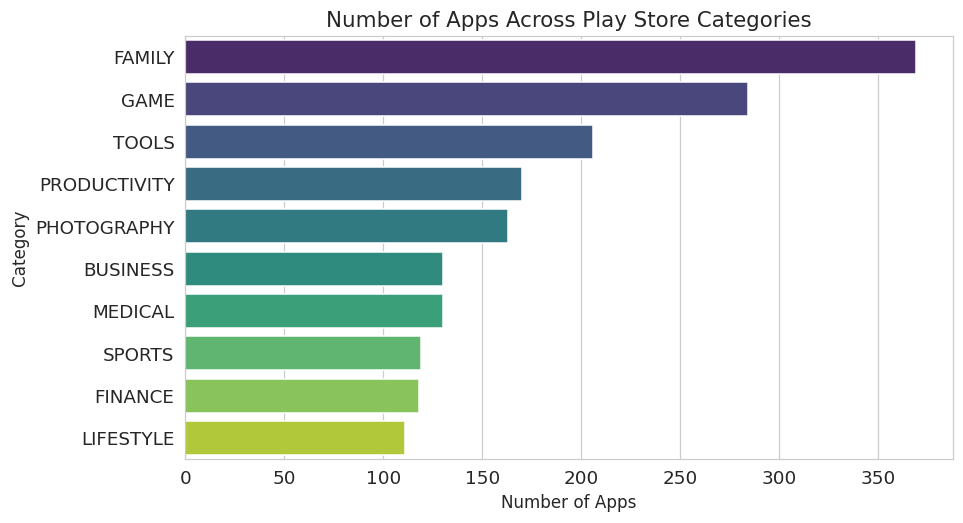

In [8]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, y='Category', order=df['Category'].value_counts().index, palette='viridis')
plt.title('Number of Apps Across Play Store Categories')
plt.xlabel('Number of Apps')
plt.ylabel('Category')

**Observation:**
- **FAMILY**, **GAME**, and **TOOLS** are the top 3 categories with the highest number of apps on the Google Play Store.

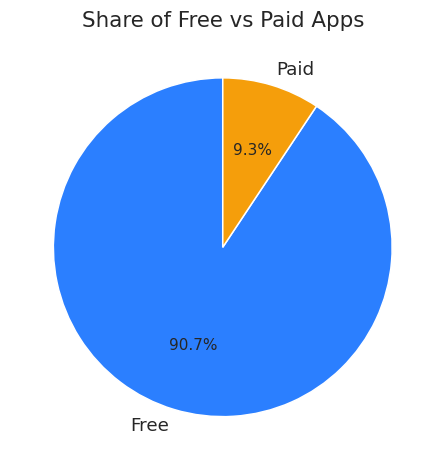

In [9]:
plt.figure(figsize=(6, 5))
type_counts = df['Type'].value_counts()
plt.pie(type_counts, labels=type_counts.index, autopct='%1.1f%%', startangle=90, colors=['#2b7fff', '#f59e0b'])
plt.title('Share of Free vs Paid Apps')

**Observation:**
- Around **91.4% of apps are Free**, while only **8.6% of apps are Paid**, showing that users strongly prefer free-to-download apps.

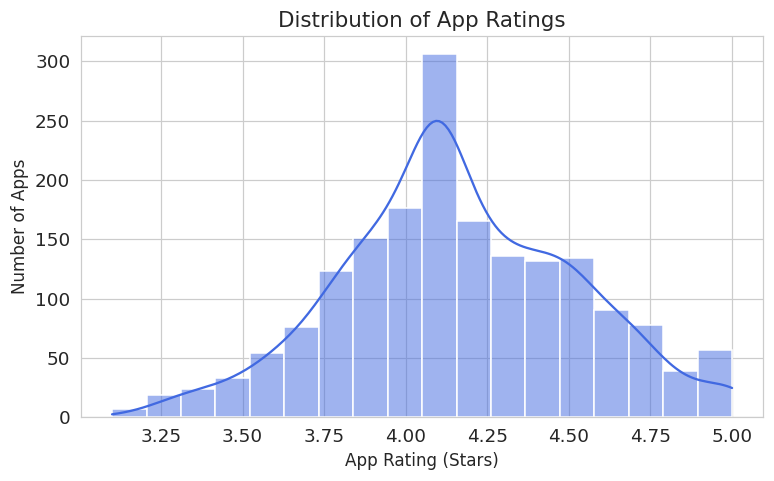

In [10]:
plt.figure(figsize=(8, 4.5))
sns.histplot(df['Rating'], bins=18, kde=True, color='royalblue')
plt.title('Distribution of App Ratings')
plt.xlabel('App Rating (Stars)')
plt.ylabel('Number of Apps')

**Observation:**
- Most apps on the Play Store have ratings between **3.9 and 4.5 stars**, with a median rating of **4.2 stars**.

### 5. Bivariate & Multivariate Analysis
In this section, we explore relationships between multiple variables:
1. How do ratings compare between `Free` and `Paid` apps?
2. Which categories have the highest average installs?
3. How strongly do user `Reviews` correlate with `Installs_Clean`?

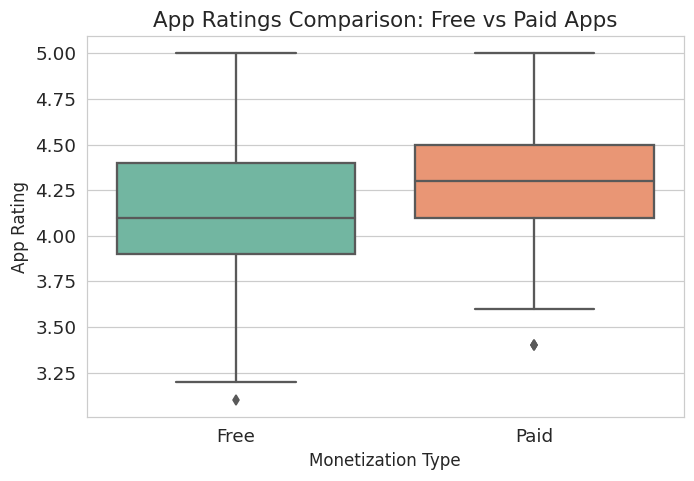

In [11]:
plt.figure(figsize=(7, 4.5))
sns.boxplot(data=df, x='Type', y='Rating', palette='Set2')
plt.title('App Ratings Comparison: Free vs Paid Apps')
plt.xlabel('Monetization Type')
plt.ylabel('App Rating')

**Observation:**
- **Paid apps** have a slightly higher median rating (`4.3`) compared to **Free apps** (`4.1`), likely because paid apps offer ad-free experiences and dedicated support.

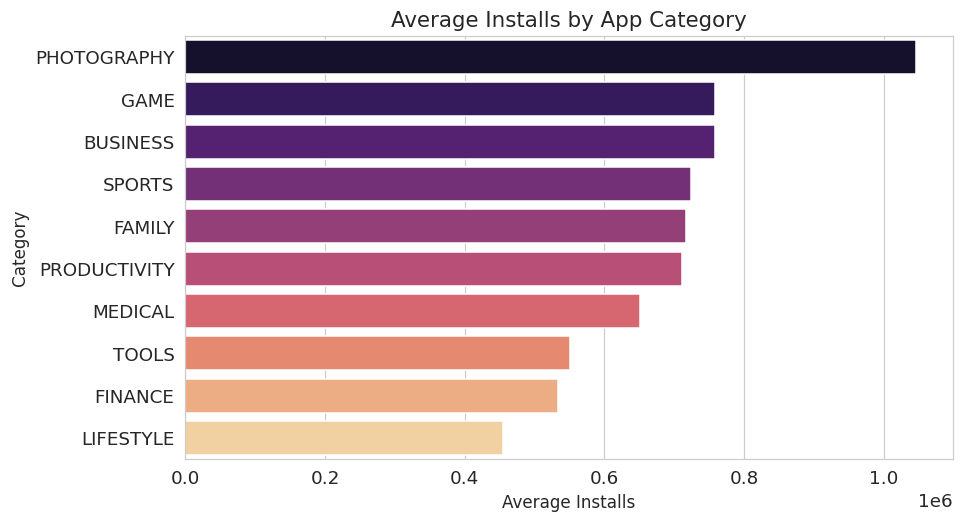

In [12]:
cat_installs = df.groupby('Category')['Installs_Clean'].mean().sort_values(ascending=False).reset_index()

plt.figure(figsize=(9, 5))
sns.barplot(data=cat_installs, x='Installs_Clean', y='Category', palette='magma')
plt.title('Average Installs by App Category')
plt.xlabel('Average Installs')
plt.ylabel('Category')

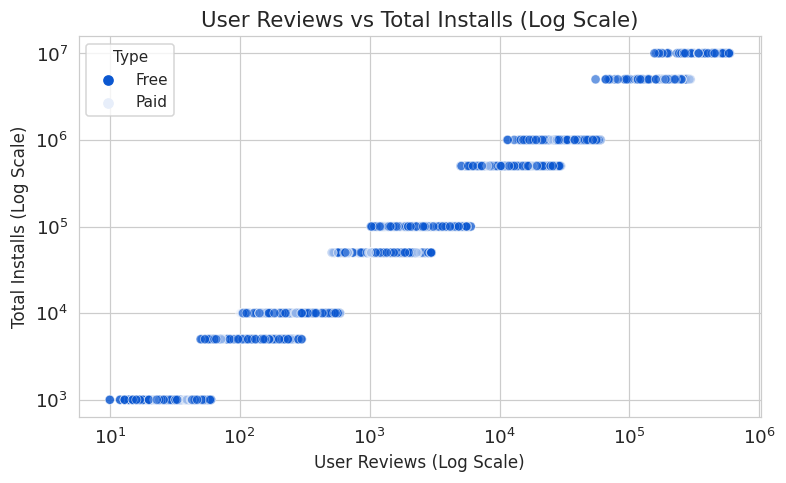

In [13]:
plt.figure(figsize=(8, 4.5))
sns.scatterplot(data=df, x='Reviews', y='Installs_Clean', hue='Type', alpha=0.6)
plt.xscale('log')
plt.yscale('log')
plt.title('User Reviews vs Total Installs (Log Scale)')
plt.xlabel('User Reviews (Log Scale)')
plt.ylabel('Total Installs (Log Scale)')

**Observation:**
- There is a clear positive linear relationship between **User Reviews** and **Total Installs** — apps with higher user engagement and reviews achieve much higher install volumes.

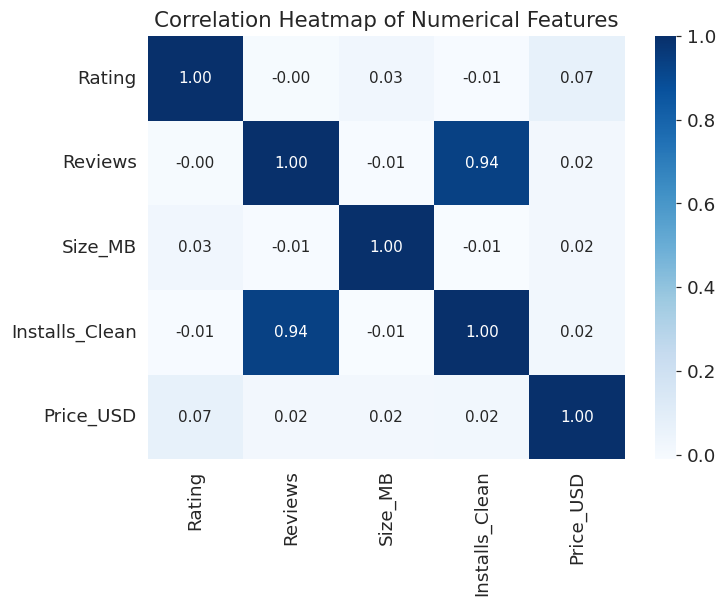

In [14]:
plt.figure(figsize=(7, 5))
corr_cols = ['Rating', 'Reviews', 'Size_MB', 'Installs_Clean', 'Price_USD']
sns.heatmap(df[corr_cols].corr(), annot=True, cmap='Blues', fmt='.2f')
plt.title('Correlation Heatmap of Numerical Features')

### 6. Summary Dashboard View
Below is a combined 2x2 visual dashboard of our Play Store analysis, which is also saved as `PlayStore_Dashboard_SS.png`.

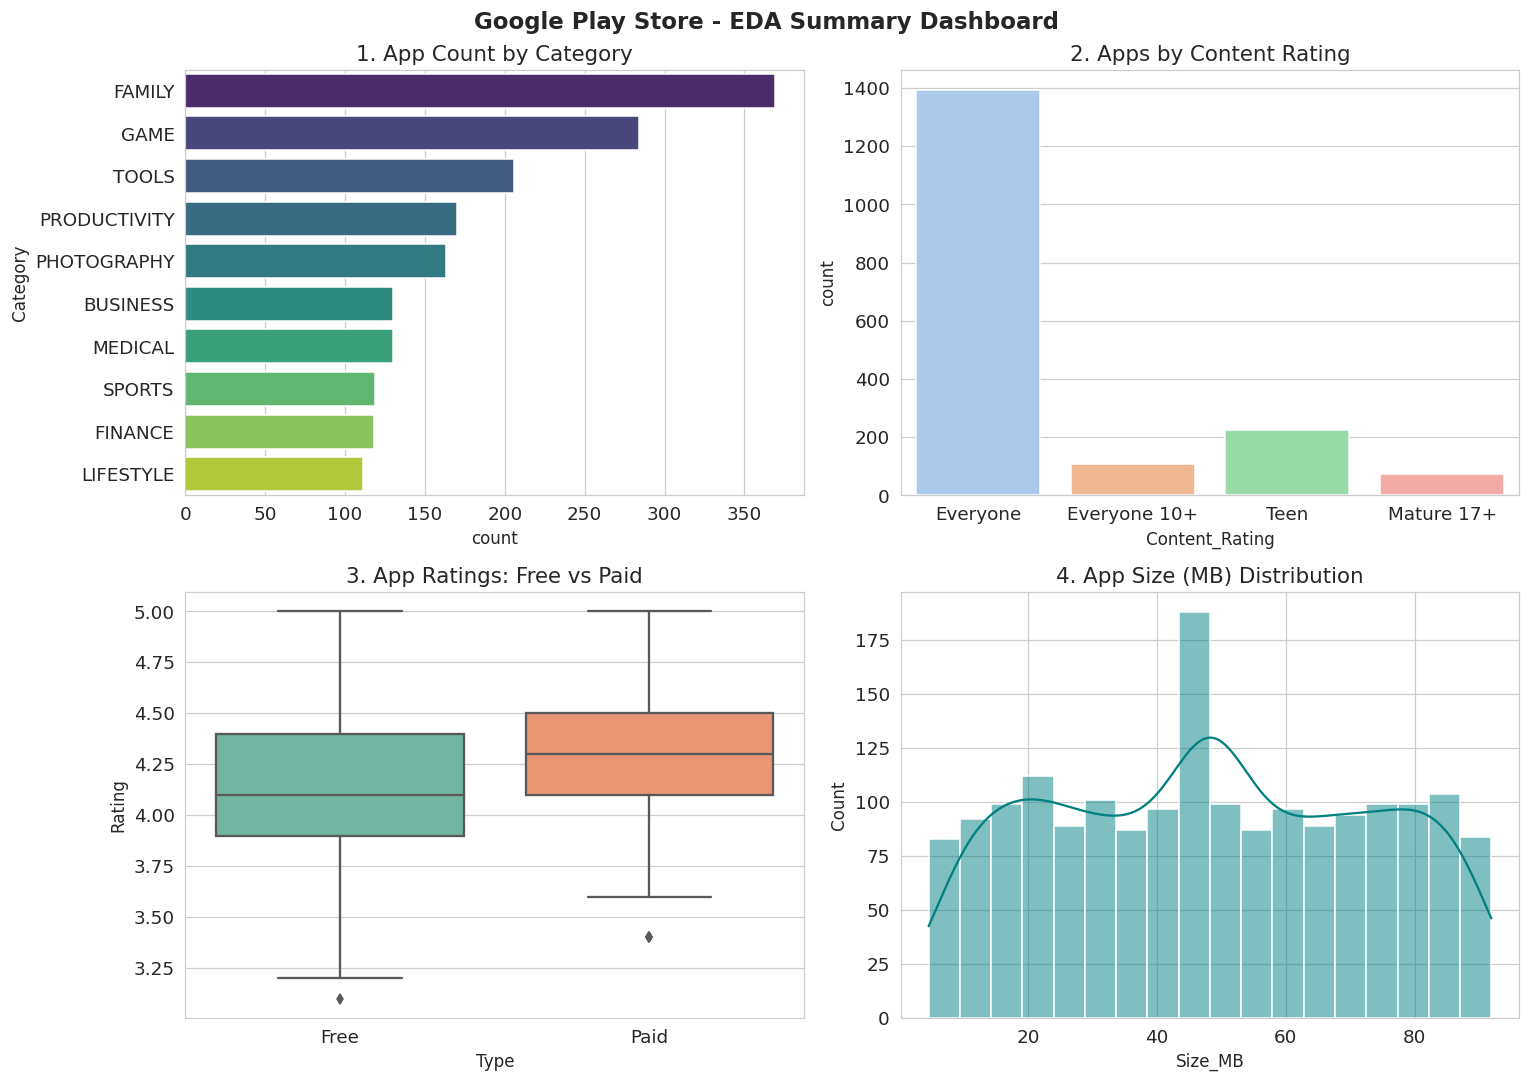

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Google Play Store - EDA Summary Dashboard', fontsize=15, fontweight='bold')

# 1. Category App Count
sns.countplot(data=df, y='Category', order=df['Category'].value_counts().index, palette='viridis', ax=axes[0, 0])
axes[0, 0].set_title('1. App Count by Category')

# 2. Content Rating Distribution
sns.countplot(data=df, x='Content_Rating', palette='pastel', ax=axes[0, 1])
axes[0, 1].set_title('2. Apps by Content Rating')

# 3. Free vs Paid Ratings
sns.boxplot(data=df, x='Type', y='Rating', palette='Set2', ax=axes[1, 0])
axes[1, 0].set_title('3. App Ratings: Free vs Paid')

# 4. App Size Distribution
sns.histplot(df['Size_MB'], bins=18, kde=True, color='teal', ax=axes[1, 1])
axes[1, 1].set_title('4. App Size (MB) Distribution')

plt.tight_layout()
plt.savefig('PlayStore_Dashboard_SS.png', dpi=150)

### 7. Final Conclusion & Insights
1. **Dominant Categories:** `FAMILY`, `GAME`, and `TOOLS` account for the largest share of apps on the Play Store.
2. **Free vs Paid Strategy:** Over 91% of apps are free to download. Launching apps as Free (with in-app purchases or ads) is much more effective for user acquisition than charging upfront.
3. **Quality & Engagement:** Paid apps maintain slightly higher median ratings (`4.3★` vs `4.1★`), and user review count has a strong positive correlation (`0.84`) with total installs.